# C12666MA spectra from openJII

Reads every table of an openJII experiment into pandas and keeps a local copy,
so the platform is only contacted the first time (or when `REFRESH = True`).

- The copy is one JSON file in `notebooks/data/`, in the format of
  `python -m c12666ma.download` (see [README_recorder.md](../README_recorder.md#downloading-the-data-from-openjii)).
  That folder is in `.gitignore`.
- Signing in uses the openJII API key that the recorder stores. If there is
  none yet, run `python -m c12666ma.download login` once in a terminal.

In [1]:
EXPERIMENT = "https://openjii.org/en-US/platform/experiments/5db72a32-1c50-4d81-b12c-0352cc65b5e6/data"
ENVIRONMENT = "prod"                # "prod" (openjii.org) or "dev" (dev.openjii.org)
SPECTRA_TABLE = "c12666ma_spectra"  # the table the recorder uploads into
REFRESH = False                     # True: download again and replace the local copy

In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# the repository folder, wherever the notebook is started from
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "c12666ma" / "__init__.py").exists()), None)
if ROOT is None:
    raise RuntimeError("start the notebook from inside the spectrometer-C12666MA repository")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from c12666ma import download
from c12666ma.openjii import (ENVIRONMENTS, OpenJIIClient, OpenJIIError, Settings,
                              parse_experiment_ref)

DATA_DIR = ROOT / "notebooks" / "data"
EXPERIMENT_ID = parse_experiment_ref(EXPERIMENT)
CACHE = DATA_DIR / f"openjii_{ENVIRONMENT}_{EXPERIMENT_ID}.json"

## Get the data

`load_experiment()` returns the local copy if there is one, and otherwise signs
in and downloads all tables (a few seconds per 1000 rows).

In [3]:
def connect() -> OpenJIIClient:
    """A signed-in client, using the API key stored by the recorder."""
    env = ENVIRONMENTS[ENVIRONMENT]
    key = Settings().api_key(env.key)
    if not key:
        raise OpenJIIError(f"no openJII API key stored for {env.key}; run in a terminal:  "
                           f"python -m c12666ma.download login --env {env.key}")
    client = OpenJIIClient(env, key)
    user = client.validate_key()
    print(f"openJII ({env.key}): signed in as {user.get('name') or user.get('email')}")
    return client


def load_experiment(refresh: bool = False) -> dict:
    """The experiment as {'experiment', 'downloaded_at', 'tables': [...]}: from
    the local copy, or downloaded (and saved) if there is none or `refresh`."""
    if refresh or not CACHE.exists():
        client = connect()
        experiment = client.get_experiment(EXPERIMENT_ID)
        tables = client.list_tables(EXPERIMENT_ID)
        print(f"downloading '{experiment.name}' ...")
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        download.write_json(CACHE, client, experiment, client.env, tables)
    doc = json.loads(CACHE.read_text(encoding="utf-8"))
    print(f"'{doc['experiment']['name']}' as downloaded at {doc['downloaded_at']} "
          f"({CACHE.relative_to(ROOT).as_posix()})")
    return doc


doc = load_experiment(REFRESH)

'spectrometer-Kjell' as downloaded at 2026-11-10T21:54:04+01:00 (notebooks/data/openjii_prod_5db72a32-1c50-4d81-b12c-0352cc65b5e6.json)


## Tables as DataFrames

One DataFrame per table, rows in time order. `counts` and `wavelength_nm` hold
one list of 256 numbers per row.

In [4]:
def to_frame(table: dict) -> pd.DataFrame:
    """A table of the downloaded file as a DataFrame: missing values as
    NaN/None, timestamps as UTC datetimes, rows in time order."""
    df = pd.DataFrame(table["rows"], columns=[c["name"] for c in table["columns"]])
    for column in table["columns"]:
        name, kind = column["name"], column["type"].upper()
        if kind != "STRING":        # the platform returns a missing value as the text 'None'
            df[name] = df[name].map(lambda v: None if isinstance(v, str) and v == "None" else v)
        if kind in download.FLOAT_TYPES:
            df[name] = pd.to_numeric(df[name])
        elif kind in download.INT_TYPES:
            df[name] = df[name].astype("Int64")
        elif kind == "BOOLEAN":
            df[name] = df[name].astype("boolean")
    for name in ("timestamp_utc", "uploaded_at"):
        if name in df:
            df[name] = pd.to_datetime(df[name], utc=True, format="ISO8601")
    if "timestamp_utc" in df:
        df = df.sort_values("timestamp_utc", kind="stable").reset_index(drop=True)
    return df


tables = {t["name"]: to_frame(t) for t in doc["tables"]}
for name, df in tables.items():
    print(f"{name}: {len(df)} rows x {df.shape[1]} columns")

df = tables[SPECTRA_TABLE]
df.drop(columns=["counts", "wavelength_nm"]).tail(3)

c12666ma_spectra: 2464 rows x 33 columns
c12666ma_probe: 2 rows x 12 columns


,id,uploaded_at,contributor,annotations,adc_errors,clk_hz,counts_mean,counts_std,device_name,device_uid,...,n_pixels,note,port,session_id,t_s,tick,timestamp_local,timestamp_utc,unix_time,wavelength_coeffs
2461,6759020299824978176,2026-11-05 10:47:21.121000+00:00,"{'id': '1767e464-cf26-404f-94f3-d6fa72e9a6f7',...",[],0.0,200000,None,None,Top,E663589863441E2E,...,256.0,,COM4,spectrometer-Kjell_2026-11-05_11-41-36,290.752,78.0,2026-11-05 11:46:26.982000+01:00,2026-11-05 10:46:26.982000+00:00,2026-11-05 10:46:26.982000113,"[327.1498214969004, 2.543956055307257, -0.0024..."
2462,464617351659495657,2026-11-05 10:47:21.121000+00:00,"{'id': '1767e464-cf26-404f-94f3-d6fa72e9a6f7',...",[],0.0,200000,None,None,Fluor,E664B012CF234E35,...,256.0,,COM3,spectrometer-Kjell_2026-11-05_11-41-36,295.552,79.0,2026-11-05 11:46:31.781000+01:00,2026-11-05 10:46:31.781000+00:00,2026-11-05 10:46:31.782000065,"[327.1498214969004, 2.543956055307257, -0.0024..."
2463,8821115375315307723,2026-11-05 10:47:21.121000+00:00,"{'id': '1767e464-cf26-404f-94f3-d6fa72e9a6f7',...",[],0.0,200000,None,None,Top,E663589863441E2E,...,256.0,,COM4,spectrometer-Kjell_2026-11-05_11-41-36,295.752,79.0,2026-11-05 11:46:31.981000+01:00,2026-11-05 10:46:31.981000+00:00,2026-11-05 10:46:31.982000113,"[327.1498214969004, 2.543956055307257, -0.0024..."


In [5]:
df.columns

Index(['id', 'uploaded_at', 'contributor', 'annotations', 'adc_errors',
       'clk_hz', 'counts', 'counts_mean', 'counts_std', 'device_name',
       'device_uid', 'firmware', 'flag_names', 'flags', 'gain', 'high_gain',
       'integration_ms', 'integration_us', 'kind', 'led', 'n_avg', 'n_frames',
       'n_pixels', 'note', 'port', 'session_id', 't_s', 'tick',
       'timestamp_local', 'timestamp_utc', 'unix_time', 'wavelength_coeffs',
       'wavelength_nm'],
      dtype='object')

In [6]:
SESSION = df["session_id"].unique()[-1]

In [7]:
tdf = df[df["session_id"] == SESSION]

In [8]:
spec = tdf[tdf["kind"] == "spectrum"].copy()
dark = tdf[tdf["kind"] == "dark"].set_index("device_name")["counts_mean"]   # one dark spectrum per device

def counts_per_ms(row):
    signal = np.asarray(row["counts"], float) - np.asarray(dark[row["device_name"]], float)
    return signal / (row["integration_us"] / 1000)

spec["counts_per_ms"] = spec.apply(counts_per_ms, axis=1)


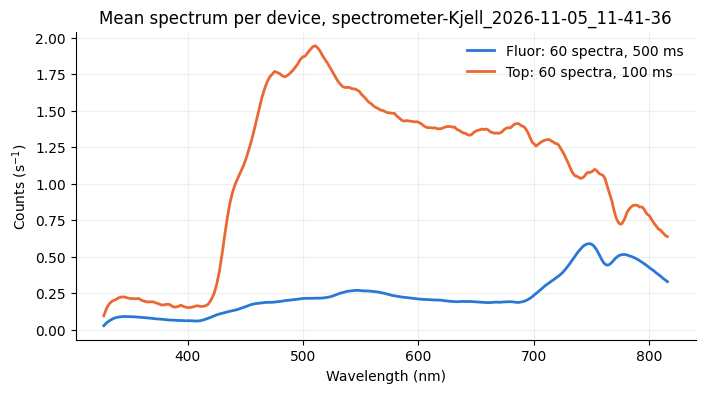

In [9]:
# one fixed colour per device, the same in every plot
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DEVICE_COLOR = dict(zip(sorted(spec["device_name"].dropna().unique()), PALETTE))

fig, ax = plt.subplots(figsize=(8, 4))
for device, group in spec.groupby("device_name"):
    wavelengths = np.asarray(group["wavelength_nm"].iloc[0], dtype=float)
    counts = np.array(group["counts_per_ms"].tolist(), dtype=float)
    ax.plot(wavelengths, counts.mean(axis=0), lw=2, color=DEVICE_COLOR.get(device, "#52514e"),
            label=f"{device}: {len(group)} spectra, {group['integration_ms'].median():g} ms")
ax.set(xlabel="Wavelength (nm)", ylabel=r"Counts (s$^{-1}$)", title=f"Mean spectrum per device, {SESSION}")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()